Title: vars_dist_comp.ipynb

Purpose: Plot the variable distributions for current and future climate

Author: Onno Nennecke on 02.06.2025 Modified: 03.11.2026

Input data: 

- Mean variable datasets

Output data:

- Some plots to compare

### Load libraries and functions

In [1]:
# Importing libraries
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
import os
from matplotlib.patches import Patch
import matplotlib as mpl

In [2]:
# Read datasets
esm_ds_cur_tas = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/tas_sp_mean_mask_ex_ws_cur.nc')
# esm_ds_fut_tas = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/tas_sp_mean_mask_ex_ws_fut.nc')
esm_ds_fut_tas = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/tas_sp_mean_mask_ex_ws_fut_2005_2024_ref.nc')

esm_ds_cur_sfcWind = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/sfcWind_sp_mean_mask_ex_ws_cur.nc')
# esm_ds_fut_sfcWind = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/sfcWind_sp_mean_mask_ex_ws_fut.nc')
esm_ds_fut_sfcWind = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/sfcWind_sp_mean_mask_ex_ws_fut_2005_2024_ref.nc')

esm_ds_cur_rsds = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/rsds_sp_mean_mask_ex_ws_cur.nc')
# esm_ds_fut_rsds = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/rsds_sp_mean_mask_ex_ws_fut.nc')
esm_ds_fut_rsds = xr.open_dataset(f'/climca/people/onennecke/model_output/var_means_masked/winter_data_condensed/rsds_sp_mean_mask_ex_ws_fut_2005_2024_ref.nc')

datasets = {
    'tas': (esm_ds_cur_tas, esm_ds_fut_tas),
    'sfcWind': (esm_ds_cur_sfcWind, esm_ds_fut_sfcWind),
    'rsds': (esm_ds_cur_rsds, esm_ds_fut_rsds)
}

In [3]:

# ── Config ────────────────────────────────────────────────────────────────────
datasets = {
    'tas':      (esm_ds_cur_tas,      esm_ds_fut_tas),
    'sfcWind':  (esm_ds_cur_sfcWind,  esm_ds_fut_sfcWind),
    'rsds':     (esm_ds_cur_rsds,     esm_ds_fut_rsds),
}
var_labels = {'tas': 'Temperature (K)', 'sfcWind': 'Wind speed (m/s)', 'rsds': 'Radiation (W/m²)'}
panel_labels = ['(a)', '(b)', '(c)']

# ── Helper: build per-ESM data dicts and summary df ───────────────────────────
def build_dicts_and_summary(esm_ds_cur, esm_ds_fut, variable_name):
    cur_dict, fut_dict = {}, {}

    # All ESMs pooled
    cur_all = esm_ds_cur[variable_name].values.ravel()
    cur_all = cur_all[~np.isnan(cur_all)]
    fut_all = esm_ds_fut[variable_name].values.ravel()
    fut_all = fut_all[~np.isnan(fut_all)]
    cur_dict['All ESMs'] = cur_all
    fut_dict['All ESMs'] = fut_all

    # Per ESM
    for esm in np.unique(esm_ds_cur.ESM.values):
        cur = esm_ds_cur.where(esm_ds_cur.ESM == esm)[variable_name].values.ravel()
        fut = esm_ds_fut.where(esm_ds_fut.ESM == esm)[variable_name].values.ravel()
        cur_dict[esm] = cur[~np.isnan(cur)]
        fut_dict[esm] = fut[~np.isnan(fut)]

    # Summary statistics
    rows = []
    for esm, cur in cur_dict.items():
        fut = fut_dict[esm]
        ks_stat, ks_p = ks_2samp(cur, fut)

        if esm != 'ERA5':
            rows.append({
                'ESM':          esm,
                'Current Mean': np.mean(cur),
                'Future Mean':  np.mean(fut),
                'Delta Mean':   np.mean(fut) - np.mean(cur),
                'Delta Mean (%)': (np.mean(fut) - np.mean(cur)) / np.mean(cur) * 100,
                'Current Std':  np.std(cur),
                'Future Std':   np.std(fut),
                'Delta Std':    np.std(fut) - np.std(cur),
                'Delta Std (%)': (np.std(fut) - np.std(cur)) / np.std(cur) * 100,
                '5pctl Current': np.percentile(cur, 5),
                '5pctl Future':  np.percentile(fut, 5),
                'Delta 5pctl': np.percentile(fut, 5) - np.percentile(cur, 5),
                'Delta 5pctl (%)': (np.percentile(fut, 5) - np.percentile(cur, 5)) / np.percentile(cur, 5) * 100,
                '95pctl Current': np.percentile(cur, 95),
                '95pctl Future':  np.percentile(fut, 95),
                'Delta 95pctl': np.percentile(fut, 95) - np.percentile(cur, 95),
                'Delta 95pctl (%)': (np.percentile(fut, 95) - np.percentile(cur, 95)) / np.percentile(cur, 95) * 100,
                'KS Statistic': ks_stat,
                'KS p-value':   ks_p,
            })
        if esm == 'ERA5':
            rows.append({
                'ESM':          esm,
                'Current Mean': np.mean(cur),
                'Future Mean':  np.nan,
                'Delta Mean':   np.nan,
                'Delta Mean (%)': np.nan,
                'Current Std':  np.std(cur),
                'Future Std':   np.nan,
                'Delta Std':    np.nan,
                'Delta Std (%)': np.nan,
                '5pctl Current': np.percentile(cur, 5),
                '5pctl Future':  np.nan,
                'Delta 5pctl': np.nan,
                'Delta 5pctl (%)': np.nan,
                '95pctl Current': np.percentile(cur, 95),
                '95pctl Future':  np.nan,
                'Delta 95pctl': np.nan,
                'Delta 95pctl (%)': np.nan,
                'KS Statistic': np.nan,
                'KS p-value':   np.nan
            })

    df = pd.DataFrame(rows)

    # Change position of the All (weighted) row to the top
    df = pd.concat([df[df['ESM'] == 'All (weighted)'], df[df['ESM'] != 'All (weighted)']], ignore_index=True)
    # Change the position of ERA5 to the top of the dataframe
    df = pd.concat([df[df['ESM'] == 'ERA5'], df[df['ESM'] != 'ERA5']], ignore_index=True)
    return cur_dict, fut_dict, df




In [4]:
cur_dict, fut_dict, summary_df = build_dicts_and_summary(
        esm_ds_cur_tas, esm_ds_fut_tas, 'tas'
    )
summary_df

/tmp/ipykernel_172010/4016146228.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


,ESM,Current Mean,Future Mean,Delta Mean,Delta Mean (%),Current Std,Future Std,Delta Std,Delta Std (%),5pctl Current,5pctl Future,Delta 5pctl,Delta 5pctl (%),95pctl Current,95pctl Future,Delta 95pctl,Delta 95pctl (%),KS Statistic,KS p-value
0,ERA5,5.108118,NaN,NaN,NaN,4.201969,NaN,NaN,NaN,-1.497478,NaN,NaN,NaN,12.500389,NaN,NaN,NaN,NaN,NaN
1,All ESMs,5.336105,6.236778,0.900673,16.878855,4.592158,4.478438,-0.113720,-2.476394,-2.224365,-1.013675,1.210690,-54.428577,13.065860,13.929295,0.863435,6.608327,0.082322,0.000000e+00
2,ACCESS-CM2,3.652143,4.881189,1.229047,33.652752,4.233135,4.238858,0.005723,0.135207,-2.996545,-1.634103,1.362442,-45.467087,11.174639,12.614309,1.439671,12.883374,0.115751,2.897349e-32
3,BCC-CSM2-M,4.574496,5.628004,1.053508,23.030031,4.418561,4.416634,-0.001927,-0.043609,-2.579046,-1.256634,1.322412,-51.275230,11.826540,13.329701,1.503161,12.710069,0.107692,1.314639e-09
4,CESM2,6.460583,7.290457,0.829874,12.845188,4.139094,4.022328,-0.116766,-2.821051,-0.176469,0.946858,1.123328,-636.556763,13.759830,14.526340,0.766510,5.570636,0.083591,0.000000e+00
5,EC-Earth3,4.019309,5.044957,1.025648,25.518021,4.766663,4.668802,-0.097861,-2.053025,-4.083025,-2.630549,1.452475,-35.573509,11.943920,12.982157,1.038237,8.692595,0.091850,0.000000e+00
6,GFDL-ESM4,3.609792,4.700999,1.091208,30.229097,4.568510,4.447091,-0.121419,-2.657747,-3.619380,-2.453929,1.165451,-32.200294,11.362820,11.824805,0.461986,4.065765,0.125275,7.365755e-13
7,KACE-1-0-G,3.895496,5.061219,1.165723,29.924902,4.854356,4.837720,-0.016636,-0.342710,-3.980356,-2.318144,1.662212,-41.760380,12.708899,13.999142,1.290242,10.152273,0.094505,1.238914e-21
8,MPI-ESM1-2,3.633708,4.591387,0.957678,26.355398,4.628070,4.534640,-0.093430,-2.018769,-4.296361,-2.603915,1.692446,-39.392536,11.449360,12.560745,1.111385,9.706965,0.079011,7.362941e-50
9,MRI-ESM2-0,5.752363,6.285972,0.533609,9.276342,4.160415,4.193325,0.032909,0.791012,-0.934518,-0.211226,0.723293,-77.397362,12.821324,13.637958,0.816633,6.369336,0.046703,4.765401e-09


In [5]:
cur_dict, fut_dict, summary_df = build_dicts_and_summary(
        esm_ds_cur_sfcWind, esm_ds_fut_sfcWind, 'sfcWind'
    )
summary_df

/tmp/ipykernel_172010/4016146228.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


,ESM,Current Mean,Future Mean,Delta Mean,Delta Mean (%),Current Std,Future Std,Delta Std,Delta Std (%),5pctl Current,5pctl Future,Delta 5pctl,Delta 5pctl (%),95pctl Current,95pctl Future,Delta 95pctl,Delta 95pctl (%),KS Statistic,KS p-value
0,ERA5,6.338730,NaN,NaN,NaN,2.312808,NaN,NaN,NaN,3.125539,NaN,NaN,NaN,10.726143,NaN,NaN,NaN,NaN,NaN
1,All ESMs,5.767180,5.768574,0.001394,0.024169,2.164288,2.190787,0.026499,1.224375,2.869164,2.846680,-0.022484,-0.783647,9.847001,9.879172,0.032171,0.326706,0.003854,1.096227e-02
2,ACCESS-CM2,5.732692,5.664452,-0.068240,-1.190360,2.162642,2.196326,0.033683,1.557510,2.802017,2.724634,-0.077383,-2.761677,9.790804,9.767591,-0.023213,-0.237086,0.023810,9.051929e-02
3,BCC-CSM2-M,6.588217,6.889091,0.300874,4.566851,1.930841,1.982917,0.052076,2.697077,3.689633,3.905487,0.215854,5.850293,10.064649,10.384411,0.319763,3.177090,0.073077,1.195141e-04
4,CESM2,5.197128,5.226018,0.028890,0.555879,1.827644,1.851291,0.023647,1.293841,2.657966,2.647104,-0.010863,-0.408678,8.563574,8.646261,0.082687,0.965572,0.008738,1.209252e-06
5,EC-Earth3,6.688601,6.696710,0.008108,0.121228,2.364467,2.437737,0.073270,3.098800,3.632865,3.580666,-0.052199,-1.436864,11.250648,11.428875,0.178227,1.584148,0.011549,4.026617e-06
6,GFDL-ESM4,7.048868,6.665263,-0.383605,-5.442081,2.368235,2.343342,-0.024894,-1.051151,3.670536,3.373348,-0.297188,-8.096578,11.249069,10.854779,-0.394290,-3.505091,0.085714,3.078659e-06
7,KACE-1-0-G,6.786740,6.861154,0.074413,1.096450,2.193910,2.184828,-0.009082,-0.413958,3.704896,3.774280,0.069383,1.872747,10.860848,10.818567,-0.042281,-0.389294,0.019048,2.751695e-01
8,MPI-ESM1-2,6.308161,6.223633,-0.084527,-1.339969,2.354647,2.315751,-0.038896,-1.651881,3.075879,3.020180,-0.055699,-1.810840,10.743666,10.527093,-0.216574,-2.015825,0.016209,1.658237e-02
9,MRI-ESM2-0,5.712453,5.670933,-0.041521,-0.726848,1.921120,1.928787,0.007667,0.399088,2.991480,2.949092,-0.042388,-1.416948,9.238886,9.235343,-0.003542,-0.038343,0.016484,1.686455e-01


In [6]:
cur_dict, fut_dict, summary_df = build_dicts_and_summary(
        esm_ds_cur_rsds, esm_ds_fut_rsds, 'rsds'
    )
summary_df

/tmp/ipykernel_172010/4016146228.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


,ESM,Current Mean,Future Mean,Delta Mean,Delta Mean (%),Current Std,Future Std,Delta Std,Delta Std (%),5pctl Current,5pctl Future,Delta 5pctl,Delta 5pctl (%),95pctl Current,95pctl Future,Delta 95pctl,Delta 95pctl (%),KS Statistic,KS p-value
0,ERA5,59.991802,NaN,NaN,NaN,39.412170,NaN,NaN,NaN,18.084637,NaN,NaN,NaN,139.092743,NaN,NaN,NaN,NaN,NaN
1,All ESMs,59.937614,59.968796,0.031181,0.052023,39.699478,39.803707,0.104229,0.262545,16.849949,16.902702,0.052753,0.313078,140.456345,141.097565,0.641220,0.456526,0.002154,0.390030
2,ACCESS-CM2,53.642239,54.589436,0.947197,1.765767,33.390251,34.481960,1.091709,3.269545,16.813540,17.245577,0.432037,2.569580,120.331963,123.591110,3.259148,2.708464,0.016850,0.420396
3,BCC-CSM2-M,47.889801,47.867607,-0.022194,-0.046344,37.043804,38.780952,1.737148,4.689444,9.822356,9.441451,-0.380905,-3.877941,126.478867,130.321884,3.843018,3.038466,0.028022,0.472569
4,CESM2,60.037201,60.277740,0.240540,0.400651,41.393063,41.443733,0.050671,0.122413,15.873830,16.133871,0.260041,1.638176,145.220047,145.836761,0.616714,0.424676,0.004785,0.027263
5,EC-Earth3,61.604763,60.962811,-0.641953,-1.042050,37.477749,37.472717,-0.005032,-0.013426,19.900827,19.495136,-0.405691,-2.038564,136.333420,136.107361,-0.226059,-0.165813,0.011477,0.000005
6,GFDL-ESM4,54.001675,54.100342,0.098667,0.182711,34.764797,35.528622,0.763824,2.197120,14.947686,14.939774,-0.007913,-0.052936,123.163948,124.597313,1.433365,1.163786,0.027473,0.498278
7,KACE-1-0-G,57.115280,58.141182,1.025902,1.796195,37.018215,38.298206,1.279991,3.457733,17.090977,16.757141,-0.333836,-1.953286,131.427246,136.218781,4.791534,3.645770,0.019231,0.264911
8,MPI-ESM1-2,51.144432,50.798237,-0.346195,-0.676897,35.672249,35.972897,0.300648,0.842806,13.798655,13.562221,-0.236434,-1.713457,124.856094,124.779816,-0.076279,-0.061093,0.018077,0.005162
9,MRI-ESM2-0,63.438206,64.460701,1.022495,1.611797,40.633007,40.529999,-0.103008,-0.253509,19.112482,19.721657,0.609175,3.187314,147.424255,147.154541,-0.269714,-0.182951,0.018242,0.096801


/tmp/ipykernel_172010/4016146228.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)
/tmp/ipykernel_172010/4016146228.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


Variable: sfcWind


/tmp/ipykernel_172010/4016146228.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


Variable: rsds


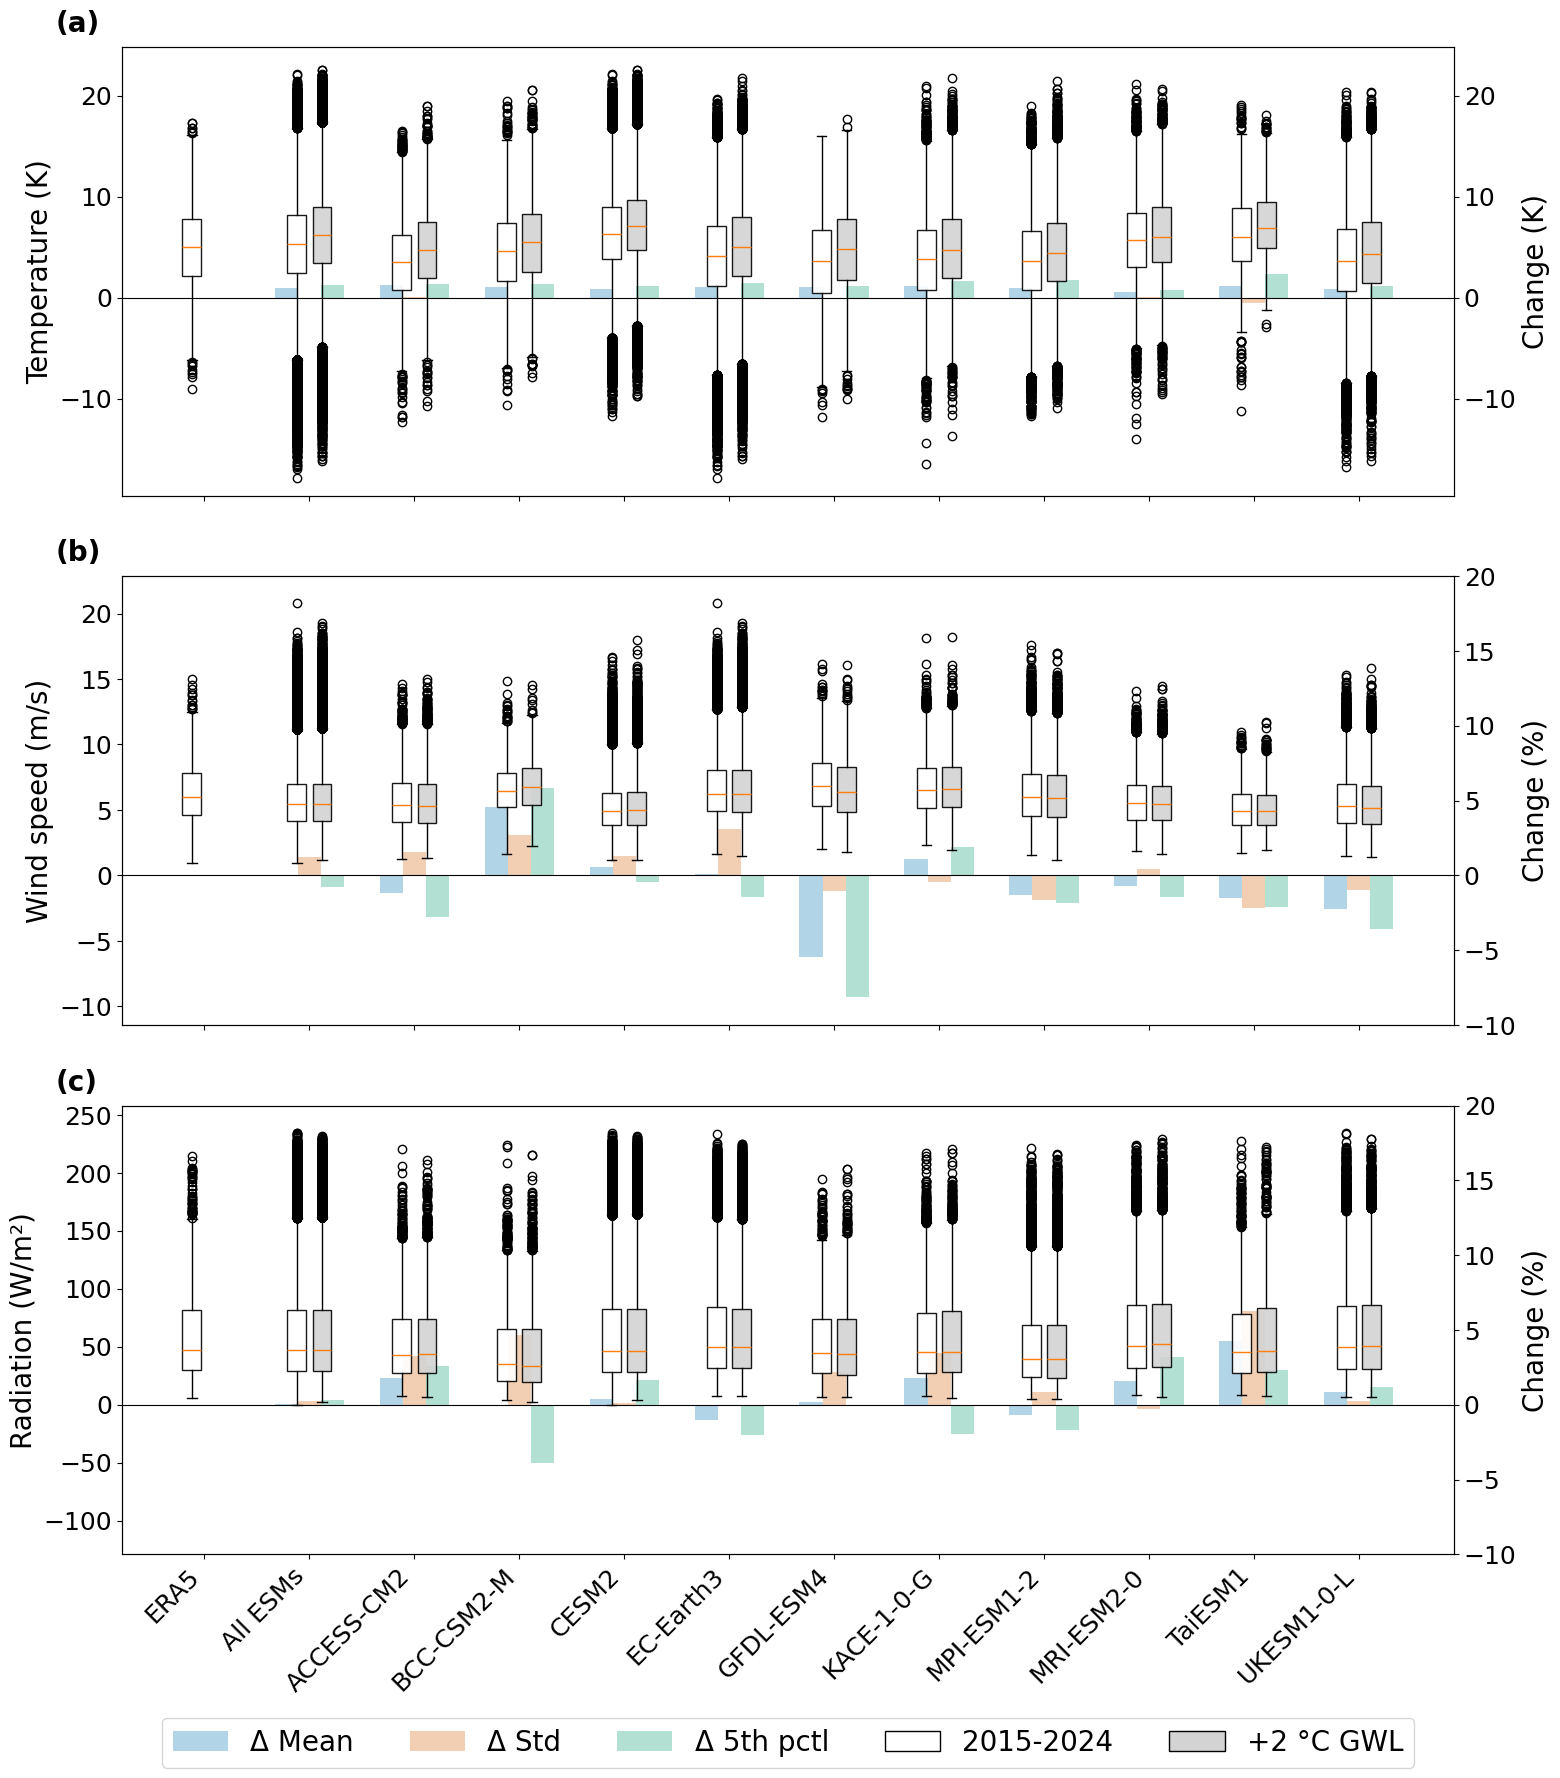

In [ ]:
mpl.rcParams.update({
    'font.size': 16+4,
    'axes.titlesize': 18+4,
    'axes.labelsize': 16+4,
    'xtick.labelsize': 14+4,
    'ytick.labelsize': 14+4,
    'legend.fontsize': 16+4,
})

fig, axes = plt.subplots(3, 1, figsize=(16, 18))

# Fixed secondary-axis range for the % panels (b) and (c)
PCT_YMIN, PCT_YMAX = -10, 20
zero_frac_below = -PCT_YMIN / (PCT_YMAX - PCT_YMIN)  # fraction of range below 0
zero_frac_above =  PCT_YMAX / (PCT_YMAX - PCT_YMIN)  # fraction of range above 0

for ax_box, (variable_name, (esm_ds_cur, esm_ds_fut)), panel in zip(
    axes, datasets.items(), panel_labels
):
    cur_dict, fut_dict, summary_df = build_dicts_and_summary(
        esm_ds_cur, esm_ds_fut, variable_name
    )

    esms = summary_df['ESM'].values
    if variable_name != 'tas':
        print(f"Variable: {variable_name}")
        delta_mean   = summary_df['Delta Mean (%)'].values
        delta_Std    = summary_df['Delta Std (%)'].values
        delta_5pctl  = summary_df['Delta 5pctl (%)'].values
    else:
        delta_mean   = summary_df['Delta Mean'].values
        delta_Std    = summary_df['Delta Std'].values
        delta_5pctl  = summary_df['Delta 5pctl'].values
    n = len(esms)
    x = np.arange(n)

    current_data = [cur_dict[k] for k in esms]
    future_data  = [fut_dict[k] for k in esms]

    ax_bar = ax_box.twinx()

    # ── Bars ──────────────────────────────────────────────────────────────────
    bar_width = 0.22
    ax_bar.bar(x - bar_width, delta_mean,  width=bar_width,
               color='#0072B2',   alpha=0.30, label='Δ Mean',  zorder=1)
    ax_bar.bar(x,              delta_Std,  width=bar_width,
               color='#D55E00',    alpha=0.30, label='Δ Std',   zorder=1)
    ax_bar.bar(x + bar_width,  delta_5pctl, width=bar_width,
               color='#009E73',  alpha=0.30, label='Δ 5th pctl', zorder=1)

    # ── Boxplots ──────────────────────────────────────────────────────────────
    offset = 0.12
    bp1 = ax_box.boxplot(current_data, positions=x - offset, widths=0.18,
                         patch_artist=True, manage_ticks=False,
                         showfliers=True, zorder=3)
    bp2 = ax_box.boxplot(future_data,  positions=x + offset, widths=0.18,
                         patch_artist=True, manage_ticks=False,
                         showfliers=True, zorder=3)

    for box in bp1['boxes']:
        box.set(facecolor='white',     edgecolor='black', alpha=0.9)
    for box in bp2['boxes']:
        box.set(facecolor='lightgray', edgecolor='black', alpha=0.9)

    # ── Axis limits ─────────────────────────────────────────────────────────
    all_vals = np.concatenate([np.concatenate(current_data),
                               np.concatenate(future_data)])

    if variable_name != 'tas':
        # Fixed % range on the bar axis
        ax_bar.set_ylim(PCT_YMIN, PCT_YMAX)

        # Match the box axis so its zero sits at the same fraction as the bar axis's zero
        vmin = np.nanmin(all_vals)
        vmax = np.nanmax(all_vals)
        R_from_min = (-vmin) / zero_frac_below if vmin < 0 else 0
        R_from_max = vmax / zero_frac_above if vmax > 0 else 0
        R = 1.1 * max(R_from_min, R_from_max)

        box_ymin = -R * zero_frac_below
        box_ymax =  R * zero_frac_above
        ax_box.set_ylim(box_ymin, box_ymax)
    else:
        # Panel (a): keep original symmetric behavior (absolute K units)
        vmin = np.nanmin(np.concatenate([all_vals, delta_mean, delta_Std, delta_5pctl]))
        vmax = np.nanmax(np.concatenate([np.abs(all_vals), np.abs(delta_mean),
                                          np.abs(delta_Std), np.abs(delta_5pctl)]))
        ax_box.set_ylim(1.1 * vmin, 1.1 * vmax)
        ax_bar.set_ylim(1.1 * vmin, 1.1 * vmax)

    ax_box.axhline(0, color='black', linewidth=0.8, zorder=2)

    # ── Labels ────────────────────────────────────────────────────────────────
    ax_box.set_ylabel(var_labels[variable_name])
    if variable_name != 'tas':
        ax_bar.set_ylabel('Change (%)')
    else:
        ax_bar.set_ylabel('Change (K)')

    if variable_name == 'rsds':
        ax_box.set_xticks(x)
        ax_box.set_xticklabels(esms, rotation=45, ha='right')
    else:
        ax_box.set_xticks(x)
        ax_box.set_xticklabels("", rotation=45, ha='right')

    ax_box.set_zorder(2)
    ax_bar.set_zorder(1)
    ax_box.patch.set_alpha(0)

    ax_box.text(-0.05, 1.02, panel, transform=ax_box.transAxes,
                fontsize=20, fontweight='bold', va='bottom')

    legend_elements = [
        Patch(facecolor='#0072B2',  alpha=0.30, label='Δ Mean'),
        Patch(facecolor='#D55E00',   alpha=0.30, label='Δ Std'),
        Patch(facecolor='#009E73', alpha=0.30, label='Δ 5th pctl'),
        Patch(facecolor='white',     edgecolor='black', label='2015-2024'),
        Patch(facecolor='lightgray', edgecolor='black', label='+2 °C GWL'),
    ]
    if variable_name == 'rsds':
        ax_box.legend(handles=legend_elements, ncol=5, loc='center',
                      bbox_to_anchor=(0.5, -0.42), bbox_transform=ax_box.transAxes)

# plt.suptitle('Current and Future Distributions with Change in Mean and Standard Deviation', y=0.98)
plt.tight_layout()
# plt.savefig('/home/onennecke/Code/Figures/vars_dist_comp.png', dpi=300, bbox_inches='tight')
plt.show()

## Old plots only std or 5 pctl old second y axis

/tmp/ipykernel_902818/407562558.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)
/tmp/ipykernel_902818/407562558.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


Variable: sfcWind


/tmp/ipykernel_902818/407562558.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


Variable: rsds


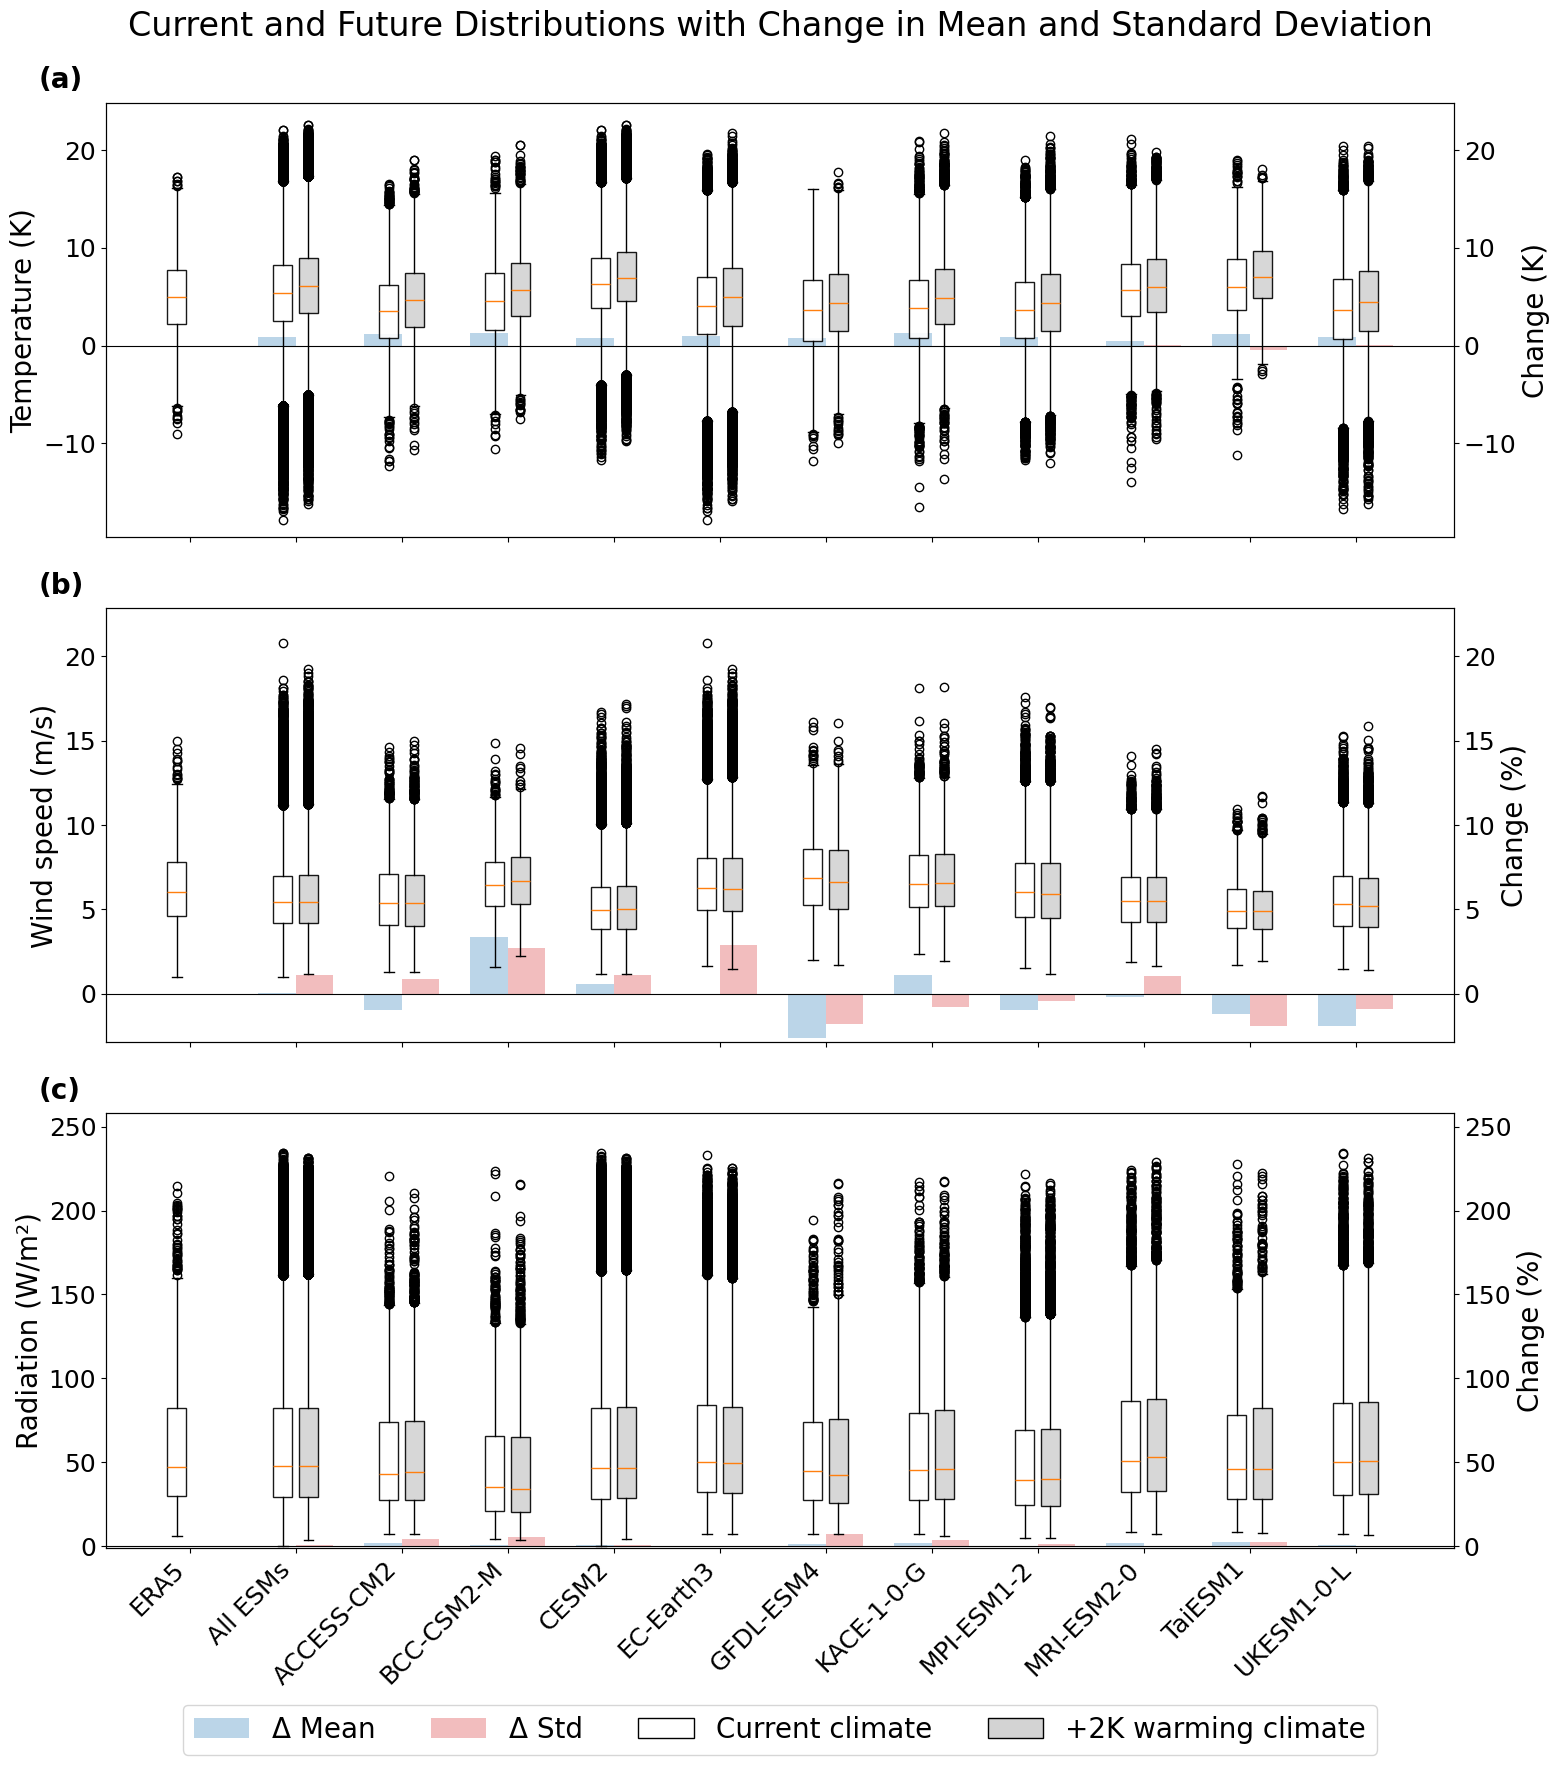

In [5]:
mpl.rcParams.update({
    'font.size': 16+4,
    'axes.titlesize': 18+4,
    'axes.labelsize': 16+4,
    'xtick.labelsize': 14+4,
    'ytick.labelsize': 14+4,
    'legend.fontsize': 16+4,
})
# import warnings
# warnings.filterwarnings('ignore')
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 18))

for ax_box, (variable_name, (esm_ds_cur, esm_ds_fut)), panel in zip(
    axes, datasets.items(), panel_labels
):
    cur_dict, fut_dict, summary_df = build_dicts_and_summary(
        esm_ds_cur, esm_ds_fut, variable_name
    )

    esms        = summary_df['ESM'].values
    if variable_name != 'tas':
        print(f"Variable: {variable_name}")
        delta_mean  = summary_df['Delta Mean (%)'].values
        delta_Std   = summary_df['Delta Std (%)'].values
    else:
        delta_mean  = summary_df['Delta Mean'].values
        delta_Std   = summary_df['Delta Std'].values
    n           = len(esms)
    x           = np.arange(n)

    current_data = [cur_dict[k] for k in esms]
    future_data  = [fut_dict[k] for k in esms]

    ax_bar = ax_box.twinx()

    # ── Bars ──────────────────────────────────────────────────────────────────
    bar_width = 0.35
    ax_bar.bar(x - bar_width / 2, delta_mean, width=bar_width,
               color='tab:blue', alpha=0.30, label='Δ Mean', zorder=1)
    ax_bar.bar(x + bar_width / 2, delta_Std,  width=bar_width,
               color='tab:red',  alpha=0.30, label='Δ Std',  zorder=1)

    # ── Boxplots ──────────────────────────────────────────────────────────────
    offset = 0.12
    bp1 = ax_box.boxplot(current_data, positions=x - offset, widths=0.18,
                         patch_artist=True, manage_ticks=False,
                         showfliers=True, zorder=3)
    bp2 = ax_box.boxplot(future_data,  positions=x + offset, widths=0.18,
                         patch_artist=True, manage_ticks=False,
                         showfliers=True, zorder=3)

    for box in bp1['boxes']:
        box.set(facecolor='white',     edgecolor='black', alpha=0.9)
    for box in bp2['boxes']:
        box.set(facecolor='lightgray', edgecolor='black', alpha=0.9)

    # ── Axis limits (shared scale so bars and boxes are comparable) ───────────
    all_vals = np.concatenate([np.concatenate(current_data),
                               np.concatenate(future_data)])
    vmin = np.nanmin(np.concatenate([all_vals, delta_mean, delta_Std]))
    vmax = np.nanmax(np.concatenate([np.abs(all_vals), np.abs(delta_mean), np.abs(delta_Std)]))
    ax_box.set_ylim(1.1 * vmin, 1.1 * vmax)
    ax_bar.set_ylim(1.1 * vmin, 1.1 * vmax)

    ax_box.axhline(0, color='black', linewidth=0.8, zorder=2)

    # ── Labels ────────────────────────────────────────────────────────────────
    ax_box.set_ylabel(var_labels[variable_name])
    if variable_name != 'tas':
        ax_bar.set_ylabel('Change (%)')
    else:
        ax_bar.set_ylabel('Change (K)')
    
    if variable_name == 'rsds':
        ax_box.set_xticks(x)
        ax_box.set_xticklabels(esms, rotation=45, ha='right')
    else:
        ax_box.set_xticks(x)
        ax_box.set_xticklabels("", rotation=45, ha='right')

    # ── Z-order so boxplots sit above bars ────────────────────────────────────
    ax_box.set_zorder(2)
    ax_bar.set_zorder(1)
    ax_box.patch.set_alpha(0)

    # ── Panel label & legend ──────────────────────────────────────────────────
    ax_box.text(-0.05, 1.02, panel, transform=ax_box.transAxes,
                fontsize=20, fontweight='bold', va='bottom')

    legend_elements = [
        Patch(facecolor='tab:blue', alpha=0.30, label='Δ Mean'),
        Patch(facecolor='tab:red',  alpha=0.30, label='Δ Std'),
        Patch(facecolor='white',     edgecolor='black', label='Current climate'),
        Patch(facecolor='lightgray', edgecolor='black', label='+2K warming climate'),
    ]
    if variable_name == 'rsds':
        ax_box.legend(handles=legend_elements, ncol=4, loc='center', bbox_to_anchor=(0.5, -0.42), bbox_transform=ax_box.transAxes)

plt.suptitle('Current and Future Distributions with Change in Mean and Standard Deviation', y=0.98)
plt.tight_layout()
# plt.savefig('/home/onennecke/Code/Figures/vars_dist_comp.png', dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_801956/407562558.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)
/tmp/ipykernel_801956/407562558.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


Variable: sfcWind


/tmp/ipykernel_801956/407562558.py:33: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  ks_stat, ks_p = ks_2samp(cur, fut)


Variable: rsds


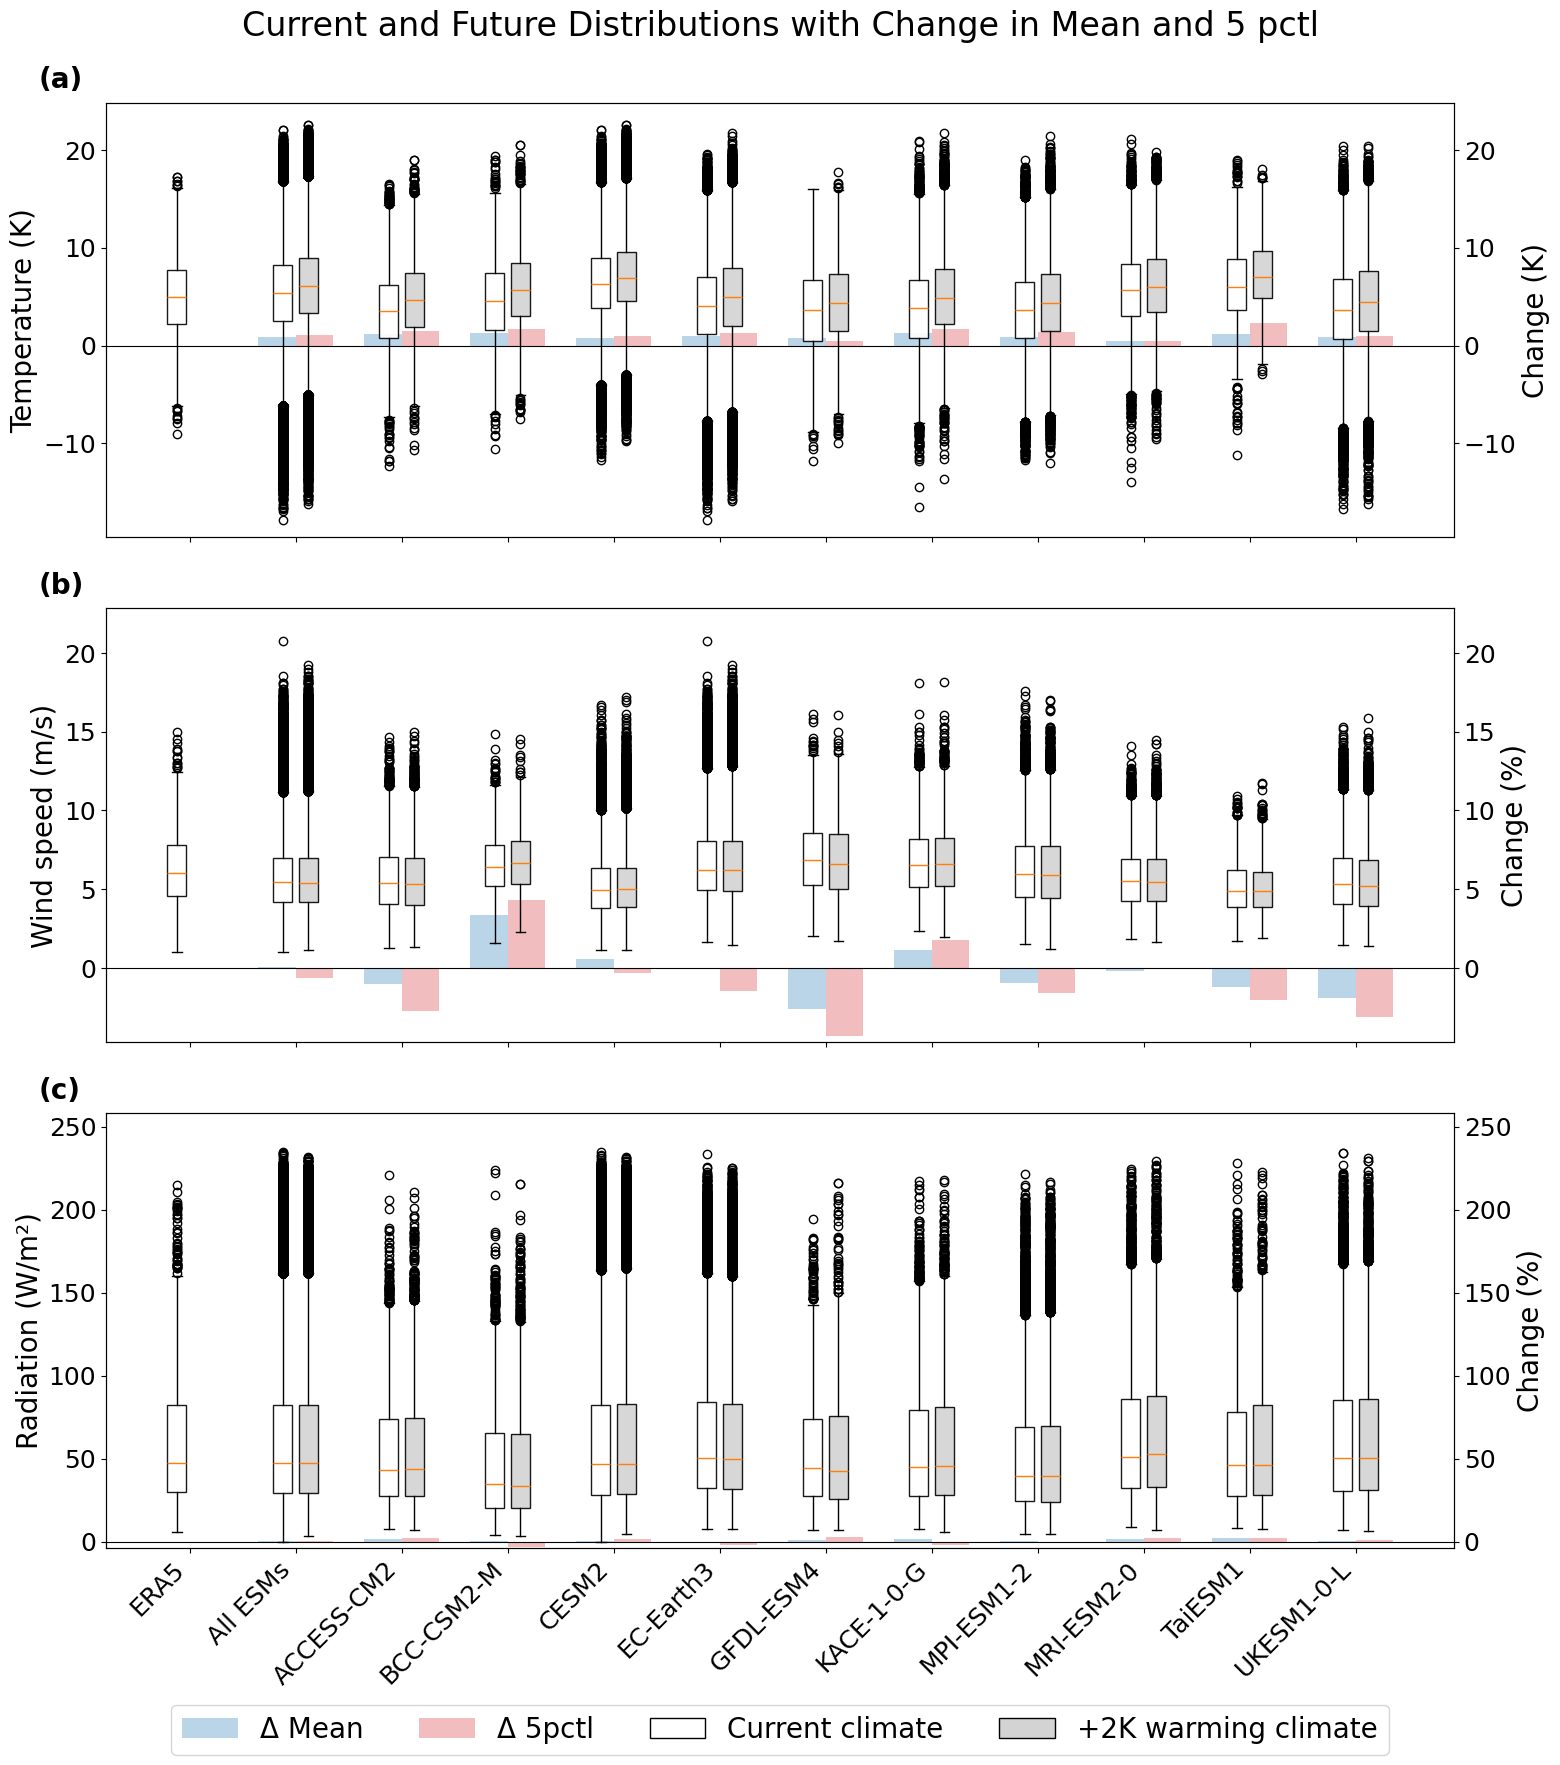

In [9]:
mpl.rcParams.update({
    'font.size': 16+4,
    'axes.titlesize': 18+4,
    'axes.labelsize': 16+4,
    'xtick.labelsize': 14+4,
    'ytick.labelsize': 14+4,
    'legend.fontsize': 16+4,
})
# import warnings
# warnings.filterwarnings('ignore')
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 18))

for ax_box, (variable_name, (esm_ds_cur, esm_ds_fut)), panel in zip(
    axes, datasets.items(), panel_labels
):
    cur_dict, fut_dict, summary_df = build_dicts_and_summary(
        esm_ds_cur, esm_ds_fut, variable_name
    )

    esms        = summary_df['ESM'].values
    if variable_name != 'tas':
        print(f"Variable: {variable_name}")
        delta_mean  = summary_df['Delta Mean (%)'].values
        delta_5pctl   = summary_df['Delta 5pctl (%)'].values
    else:
        delta_mean  = summary_df['Delta Mean'].values
        delta_5pctl   = summary_df['Delta 5pctl'].values
    n           = len(esms)
    x           = np.arange(n)

    current_data = [cur_dict[k] for k in esms]
    future_data  = [fut_dict[k] for k in esms]

    ax_bar = ax_box.twinx()

    # ── Bars ──────────────────────────────────────────────────────────────────
    bar_width = 0.35
    ax_bar.bar(x - bar_width / 2, delta_mean, width=bar_width,
               color='tab:blue', alpha=0.30, label='Δ Mean', zorder=1)
    ax_bar.bar(x + bar_width / 2, delta_5pctl,  width=bar_width,
               color='tab:red',  alpha=0.30, label='Δ 5pctl',  zorder=1)

    # ── Boxplots ──────────────────────────────────────────────────────────────
    offset = 0.12
    bp1 = ax_box.boxplot(current_data, positions=x - offset, widths=0.18,
                         patch_artist=True, manage_ticks=False,
                         showfliers=True, zorder=3)
    bp2 = ax_box.boxplot(future_data,  positions=x + offset, widths=0.18,
                         patch_artist=True, manage_ticks=False,
                         showfliers=True, zorder=3)

    for box in bp1['boxes']:
        box.set(facecolor='white',     edgecolor='black', alpha=0.9)
    for box in bp2['boxes']:
        box.set(facecolor='lightgray', edgecolor='black', alpha=0.9)

    # ── Axis limits (shared scale so bars and boxes are comparable) ───────────
    all_vals = np.concatenate([np.concatenate(current_data),
                               np.concatenate(future_data)])
    vmin = np.nanmin(np.concatenate([all_vals, delta_mean, delta_5pctl]))
    vmax = np.nanmax(np.concatenate([np.abs(all_vals), np.abs(delta_mean), np.abs(delta_5pctl)]))
    ax_box.set_ylim(1.1 * vmin, 1.1 * vmax)
    ax_bar.set_ylim(1.1 * vmin, 1.1 * vmax)

    ax_box.axhline(0, color='black', linewidth=0.8, zorder=2)

    # ── Labels ────────────────────────────────────────────────────────────────
    ax_box.set_ylabel(var_labels[variable_name])
    if variable_name != 'tas':
        ax_bar.set_ylabel('Change (%)')
    else:
        ax_bar.set_ylabel('Change (K)')
    
    if variable_name == 'rsds':
        ax_box.set_xticks(x)
        ax_box.set_xticklabels(esms, rotation=45, ha='right')
    else:
        ax_box.set_xticks(x)
        ax_box.set_xticklabels("", rotation=45, ha='right')

    # ── Z-order so boxplots sit above bars ────────────────────────────────────
    ax_box.set_zorder(2)
    ax_bar.set_zorder(1)
    ax_box.patch.set_alpha(0)

    # ── Panel label & legend ──────────────────────────────────────────────────
    ax_box.text(-0.05, 1.02, panel, transform=ax_box.transAxes,
                fontsize=20, fontweight='bold', va='bottom')

    legend_elements = [
        Patch(facecolor='tab:blue', alpha=0.30, label='Δ Mean'),
        Patch(facecolor='tab:red',  alpha=0.30, label='Δ 5pctl'),
        Patch(facecolor='white',     edgecolor='black', label='Current climate'),
        Patch(facecolor='lightgray', edgecolor='black', label='+2K warming climate'),
    ]
    if variable_name == 'rsds':
        ax_box.legend(handles=legend_elements, ncol=4, loc='center', bbox_to_anchor=(0.5, -0.42), bbox_transform=ax_box.transAxes)

plt.suptitle('Current and Future Distributions with Change in Mean and 5 pctl', y=0.98)
plt.tight_layout()
# plt.savefig('/home/onennecke/Code/Figures/vars_dist_comp.png', dpi=300, bbox_inches='tight')
plt.show()
